<a href="https://colab.research.google.com/github/sabriddinovna/graph_nn/blob/main/node_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import torch
os.environ['TORCH']= torch.__version__
print(torch.__version__)

2.11.0+cpu


In [ ]:
!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 12.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Helper function for visualization.
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt


def visualize_graph(G, color):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=42), with_labels=False,
                     node_color=color, cmap="Set2")
    plt.show()


def visualize_embedding(h, color, epoch=None, loss=None):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    h = h.detach().cpu().numpy()
    plt.scatter(h[:, 0], h[:, 1], s=140, c=color, cmap="Set2")
    if epoch is not None and loss is not None:
        plt.xlabel(f'Epoch: {epoch}, Loss: {loss.item():.4f}', fontsize=16)
    plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
import torchvision
from torchvision.transforms import v2

In [ ]:
transform=v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5),(0.5, 0.5, 0.5))
])

In [ ]:
batch_size=100

In [ ]:
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

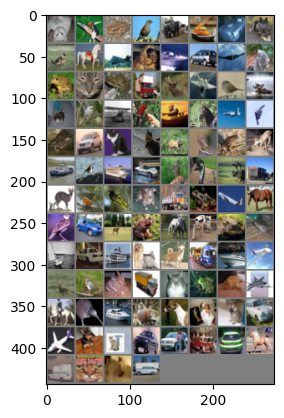

cat   bird  frog  bird  truck ship  car   dog   dog   horse plane dog   ship  car   plane cat   frog  cat   frog  truck deer  plane bird  deer  dog   bird  plane bird  plane horse plane plane frog  car   cat   cat   frog  bird  frog  deer  ship  bird  ship  car   deer  bird  deer  truck deer  deer  bird  dog   truck frog  plane horse bird  car   deer  frog  horse cat   frog  frog  ship  car   ship  dog   dog   truck ship  plane deer  bird  deer  truck cat   frog  cat   plane horse bird  ship  bird  dog   dog   dog   car   plane dog   cat   car   car   truck car   horse truck cat   cat   car  


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
  def __init__self():
    super().__init__()
    self.conv1=nn.Conv2d(3, 6, 5)
    self.pool=nn.MaxPool2d(2, 2)
    self.conv2=nn.Conv2d(6, 16, 5)
    self.fc1=nn.Linear(16*5*5,120)
    self.fc2=nn.Linear(120, 84)
    self.fc3=nn.Linear(84,10)


  def forward(self, x):
    x=self.pool(F.relu(self.conv1(x)))
    x=self.pool(F.relu(self.conv2(x)))
    x=torch.flatten(x,1)
    x=F.relu(self.fc1(x))
    x=F.relu(self.fc2(X))
    x=self.fc3(x)
    return x

net=Net()

In [ ]:
print(list(net.parameters()))

[]


In [ ]:
import torch.optim as optim
criterion=nn.CrossEntropyLoss()
optimizer= optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

ValueError: optimizer got an empty parameter list

In [ ]:
# Install required packages.
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

# Helper function for visualization.
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt


def visualize_graph(G, color):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=42), with_labels=False,
                     node_color=color, cmap="Set2")
    plt.show()


def visualize_embedding(h, color, epoch=None, loss=None):
    plt.figure(figsize=(7,7))
    plt.xticks([])
    plt.yticks([])
    h = h.detach().cpu().numpy()
    plt.scatter(h[:, 0], h[:, 1], s=140, c=color, cmap="Set2")
    if epoch is not None and loss is not None:
        plt.xlabel(f'Epoch: {epoch}, Loss: {loss.item():.4f}', fontsize=16)
    plt.show()

2.11.0+cpu
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 9.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from torch_geometric.datasets import KarateClub
dataset=KarateClub()

In [ ]:
data=dataset[0]


In [ ]:
print(data)

Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])


In [ ]:
data.num_nodes

34

In [ ]:
data.num_node_types

1

In [ ]:
data.num_edges

156

In [ ]:
!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 28.6 MB/s eta 0:00:00


In [ ]:
import torch
from torch.nn import Linear
from torch_geometric.nn import GCNConv


In [ ]:
from torch_geometric.datasets import KarateClub

In [ ]:
dataset=KarateClub()

In [ ]:
class GCN(torch.nn.Module):
  def __init__(self):
    super().__init__()
    torch.manual_seed(2344)
    self.conv1=GCNConv(dataset.num_features, 4)
    self.conv2=GCNConv(4,4)
    self.conv3=GCNConv(4,2)
    self.classifier= Linear(2, dataset.num_classes)

  def forward(self, x, edge_index):
    h=self.conv1(x, edge_index)
    h=h.tanh()
    h=self.conv2(h, edge_index)
    h=h.tanh()
    h=self.conv3(h, edge_index)
    h=h.tanh()
    out=self.classifier(h)

    return out, h

model=GCN()
print(model)



GCN(
  (conv1): GCNConv(34, 4)
  (conv2): GCNConv(4, 4)
  (conv3): GCNConv(4, 2)
  (classifier): Linear(in_features=2, out_features=4, bias=True)
)


In [ ]:
model=GCN()

In [ ]:
data=dataset[0]

In [ ]:
criterion = torch.nn.CrossEntropyLoss()
out, h = model(data.x, data.edge_index)
loss = criterion(out[data.train_mask], data.y[data.train_mask])

In [ ]:
import time
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 430})'''))


<IPython.core.display.Javascript object>

In [ ]:
model=GCN()
criterion=torch.nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(), lr=0.01)

In [ ]:
def train(data):
  optimizer.grad_zero()
  out, h=model(data.x, data.edge_index)
  loss=criterion(out[data.train_mask], data.y[data.train_mask])
  loss.backward()
  optimizer.step()

  accuracy={}
  predicted_classes=torch.argmax(out[data.train_mask], axis=1)
  target_classes=data.y[data.train_mask]
  accuracy['train']=torch.mean(
      torch.where(predicted_classes==target_classes, 1, 0).float()

  )

node embedding pipeline


In [ ]:
import networkx as nx

In [ ]:
g=nx.karate_club_graph()
type(g)

networkx.classes.graph.Graph

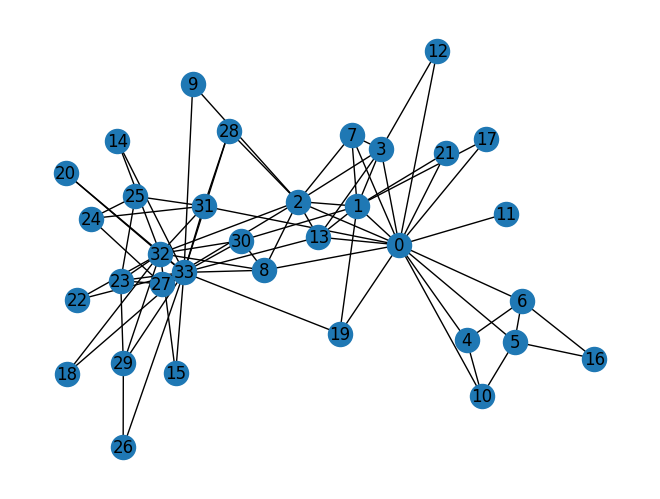

In [ ]:
nx.draw(g, with_labels=True)

In [ ]:
def avg_degree(num_edges, num_nodes):
  avg_degree=round(2*num_edges/num_nodes)

  return avg_degree

In [ ]:
def avg_clustering_coef(g):
  avg_clustering_coef=nx.average_clustering(g)

  return avg_clustering_coef

In [ ]:
import os
import torch

In [ ]:
os.environ['TORCH']=torch.__version__
print(torch.__version__)

2.11.0+cpu


In [ ]:
!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 12.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [ ]:
def visualize(h, color):
    z = TSNE(n_components=2).fit_transform(h.detach().cpu().numpy())

    plt.figure(figsize=(10,10))
    plt.xticks([])
    plt.yticks([])

    plt.scatter(z[:, 0], z[:, 1], s=70, c=color, cmap="Set2")
    plt.show()


In [14]:
!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

from matplotlib.colors import Normalize
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures

dataset=Planetoid(root='data/Planetoid', name='Cora', transform=NormalizeFeatures())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [15]:
data=dataset[0]

In [ ]:
data.num_nodes

2708

In [ ]:
data.num_edge_types

1

In [ ]:
data.num_edges

10556

In [ ]:
data.train_mask.sum()

tensor(140)

In [16]:
import torch
from torch.nn import Linear
import torch.nn.functional as F

In [22]:
class MLP(torch.nn.Module):
  def __init__(self, hidden_channels):
    super().__init__()
    torch.manual_seed(6462)
    self.lin1=Linear(dataset.num_features, hidden_channels)
    self.lin2=Linear(hidden_channels,  dataset.num_classes)

  def forward(self, x):
    x=self.lin1(x)
    x=x.relu()
    x=F.dropout(x, p=0.5, training=self.training)
    x=self.lin2(x)
    return x
model=MLP(hidden_channels=16)
print(model)


MLP(
  (lin1): Linear(in_features=1433, out_features=16, bias=True)
  (lin2): Linear(in_features=16, out_features=7, bias=True)
)


In [23]:
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 300})'''))

model = MLP(hidden_channels=16)
criterion = torch.nn.CrossEntropyLoss()  # Define loss criterion.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)  # Define optimizer.


<IPython.core.display.Javascript object>

In [24]:
def train():
  model.train()
  optimizer.zero_grad()
  out=model(data.x)
  loss=criterion(out[data.train_mask], data.y[data.train_mask])
  loss.backward()
  optimizer.step()
  return loss

In [27]:

def test():
  model.eval()
  out=model(data.x)
  pred=out.argmax(dim=1)
  test_correct=pred[data.test_mask]==data.y[data.test_mask]
  test_acc=int(test_correct.sum())/int(data.test_mask.sum())
  return test_acc

In [26]:
for epoch in range(1, 201, 35):
  loss=train()
  print(epoch, loss)

1 tensor(1.9540, grad_fn=<NllLossBackward0>)
36 tensor(1.9507, grad_fn=<NllLossBackward0>)
71 tensor(1.9460, grad_fn=<NllLossBackward0>)
106 tensor(1.9434, grad_fn=<NllLossBackward0>)
141 tensor(1.9364, grad_fn=<NllLossBackward0>)
176 tensor(1.9304, grad_fn=<NllLossBackward0>)


In [28]:
acc=test()

In [29]:
acc

0.13

In [35]:
len(dataset[0])

6

In [36]:
dataset.num_features

1433

In [34]:
from torch_geometric.nn import GCNConv
class GCN(torch.nn.Module):
  def __init__(self, hidden_channels):
    super().__init__()
    torch.manual_seed(4672)
    self.conv1=GCNConv(dataset.num_features,hidden_channels)
    self.conv2=GCNConv(hidden_channels, dataset.num_classes)

  def forward(self, x, edge_index):
    x=self.conv1(x, edge_index)
    x=x.relu()
    x=F.dropout(x, p=0.5, training=self.training)
    x=self.conv2(x, edge_index)
    return x

model=GCN(hidden_channels=16)
print(model)

GCN(
  (conv1): GCNConv(1433, 16)
  (conv2): GCNConv(16, 7)
)


In [38]:
data.edge_index

tensor([[ 633, 1862, 2582,  ...,  598, 1473, 2706],
        [   0,    0,    0,  ..., 2707, 2707, 2707]])

In [37]:
model=GCN(hidden_channels=16)
model.eval()

GCN(
  (conv1): GCNConv(1433, 16)
  (conv2): GCNConv(16, 7)
)

In [43]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE


In [44]:
def visualize(h, color):
    z = TSNE(n_components=2).fit_transform(h.detach().cpu().numpy())

    plt.figure(figsize=(10,10))
    plt.xticks([])
    plt.yticks([])

    plt.scatter(z[:, 0], z[:, 1], s=70, c=color, cmap="Set2")
    plt.show()

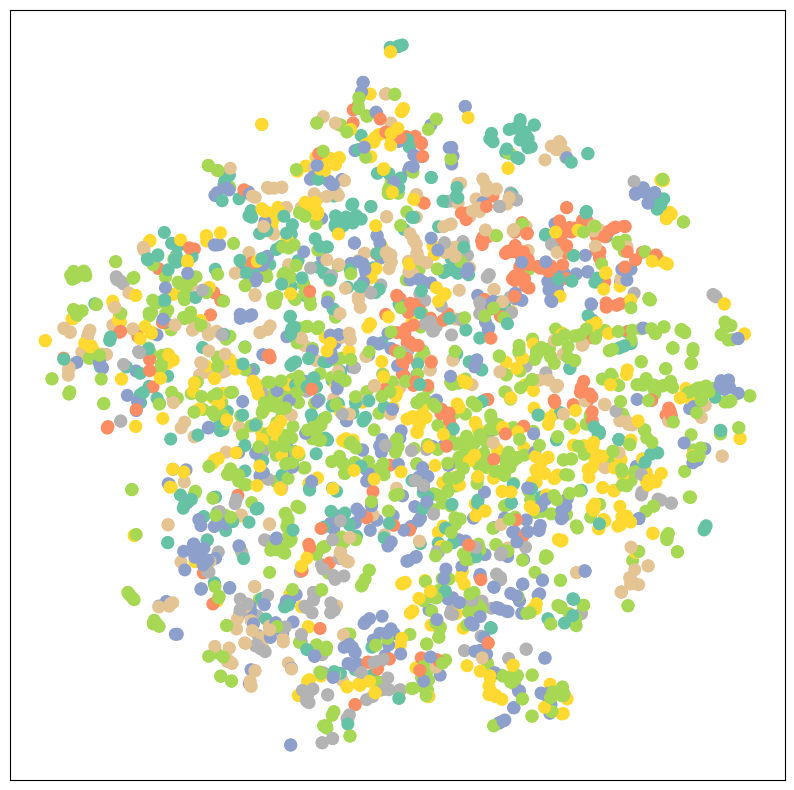

In [45]:
out=model(data.x, data.edge_index)
visualize(out, color=data.y)

data.x-node features;
edge_index-graph connectivity. we will give them into input of the GCN

In [53]:
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 300})'''))


<IPython.core.display.Javascript object>

In [47]:
model=GCN(hidden_channels=16)
optimizer=torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion=torch.nn.CrossEntropyLoss()

In [49]:
def train():
  model.train()
  optimizer.zero_grad()
  out=model(data.x, data.edge_index)
  loss=criterion(out[data.train_mask], data.y[data.train_mask])
  loss.backward()
  optimizer.step()
  return loss

def test():
  model.eval()
  out=model(data.x, data.edge_index)
  pred=out.argmax(dim=1)
  test_correct=pred[data.test_mask]==data.y[data.test_mask]
  test_acc=int(test_correct.sum())/int(data.test_mask.sum())
  return test_acc

for epoch in range(1, 100, 10):
  loss=train()
  print(epoch, loss)



1 tensor(1.9465, grad_fn=<NllLossBackward0>)
11 tensor(1.9427, grad_fn=<NllLossBackward0>)
21 tensor(1.9386, grad_fn=<NllLossBackward0>)
31 tensor(1.9331, grad_fn=<NllLossBackward0>)
41 tensor(1.9289, grad_fn=<NllLossBackward0>)
51 tensor(1.9214, grad_fn=<NllLossBackward0>)
61 tensor(1.9135, grad_fn=<NllLossBackward0>)
71 tensor(1.9042, grad_fn=<NllLossBackward0>)
81 tensor(1.8924, grad_fn=<NllLossBackward0>)
91 tensor(1.8866, grad_fn=<NllLossBackward0>)


In [50]:
acc=test()


In [51]:
acc

0.454

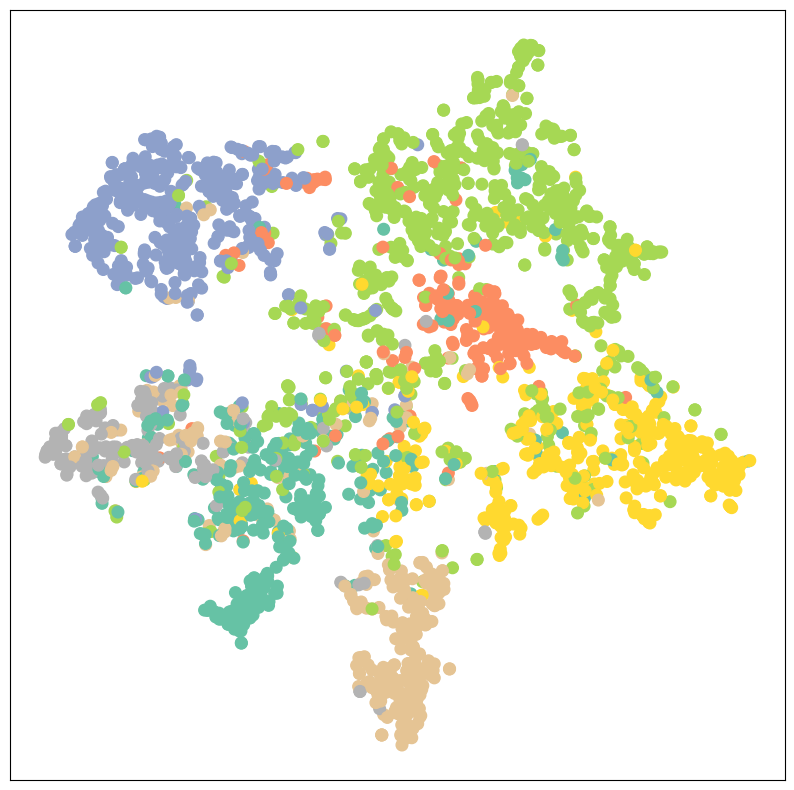

In [52]:
model.eval()

out = model(data.x, data.edge_index)
visualize(out, color=data.y)